In [1]:
import os
import sys
root = os.path.abspath("..")
sys.path.append(root)

import io
import shutil
import pickle
import torch
import re
import json
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
from datetime import datetime
from collections import defaultdict

from config import Config
from simulation.impl.trajectory_with_metrics import TrajectoryWithMetrics

if shutil.which("latex"):
    plt.style.use(["science", "ieee"])
else:
    plt.style.use(["science", "ieee", "no-latex"])

config = Config()
figures_dir = os.path.join(config.resource_dir, "figures")
os.makedirs(figures_dir, exist_ok=True)

/Users/alla1854/Documents/Documents - Alfred’s MacBook Pro/Projects/PhD/AutoscalingArchitecture/Code/.env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
class CPU_Unpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module == 'torch.storage' and name == '_load_from_bytes':
            return lambda b: torch.load(io.BytesIO(b), map_location='cpu')
        return super().find_class(module, name)

In [ ]:
TRAJECTORY_DIR = "path/to/trajectories"
EXPERIMENT_DIR = os.path.abspath("../experiments")
CLIENT_CPU_BASE = 200.0


def get_policy_label(experiment):
    policy = experiment["server_policy"]
    scale = experiment.get("server_policy_smart_priority_scale", 1.0)
    if policy == "smart" and float(scale) > 1.0:
        return "smartx"
    return policy


def load_records():
    datetimes = {}
    paths = {}
    devices = {}

    for filename in os.listdir(TRAJECTORY_DIR):
        if not filename.startswith("trajectory_exp_simulation"):
            continue
        match = re.findall(r"trajectory_exp_simulation_(.+)_(.+)_(.+)\.pkl", filename)
        if not match:
            continue
        device, idx, date_str = match[0]
        idx = int(idx)
        date_str = datetime.fromisoformat(date_str)
        if idx not in datetimes or date_str > datetimes[idx]:
            devices[idx] = device
            paths[idx] = os.path.join(TRAJECTORY_DIR, filename)
            datetimes[idx] = date_str

    records = []
    for idx, path in paths.items():
        exp_path = os.path.join(EXPERIMENT_DIR, f"exp_simulation_{devices[idx]}_{idx}.json")
        if not os.path.exists(exp_path):
            continue
        with open(exp_path) as f:
            experiment = json.load(f)
        records.append((idx, path, experiment))

    print(f"Loaded {len(records)} records")
    return records


records = load_records()

Loaded 160 records


In [4]:
POLICIES = ["centralized", "default", "smart"]  #, "smartx"]
POLICY_LABELS = ["Centralized", "Uniform", "Affinity"]  #, "SmartX"]

RESOURCES    = ["bw_in", "bw_out", "cpu", "mem"]
RESOURCE_LABELS = ["Bandwidth In", "Bandwidth Out", "CPU (\%)", "Memory (GB)"]
RESOURCE_FNAMES = ["bandwidth_in", "bandwidth_out", "cpu", "memory"]


def fmt_clients(n):
    if n >= 1000:
        return f"{n // 1000}k"
    return str(n)

In [5]:
# key: (policy, server_mult, n_clients, client_mult)
# value: list of (bw_in_mean, bw_in_std, bw_out_mean, bw_out_std, cpu_mean, cpu_std, mem_mean, mem_std)
resource_data = defaultdict(list)

_GB = 1024 ** 3

for idx, path, exp in records:
    trajectory: TrajectoryWithMetrics = CPU_Unpickler(open(path, "rb")).load()

    def _stats(lst):
        if not lst:
            return np.nan, np.nan
        arr = np.array(lst, dtype=float)
        return arr.mean(), arr.std()

    bw_in_mean,  bw_in_std  = _stats(trajectory.server_bandwidth_in_usage)
    bw_out_mean, bw_out_std = _stats(trajectory.server_bandwidth_out_usage)
    cpu_mean,    cpu_std    = _stats(trajectory.server_cpu_usage)
    mem_mean,    mem_std    = _stats([v / _GB for v in trajectory.server_memory_usage])

    policy     = get_policy_label(exp)
    server_cpu = exp["available_resource_params"]["server"]["cpu"]["max"]
    client_cpu = exp["available_resource_params"]["client"]["cpu"]["max"]
    n_clients  = exp["n_clients"]

    server_mult = int(round(server_cpu / CLIENT_CPU_BASE))
    client_mult = int(round(client_cpu / CLIENT_CPU_BASE))

    resource_data[(policy, server_mult, n_clients, client_mult)].append(
        (bw_in_mean, bw_in_std, bw_out_mean, bw_out_std, cpu_mean, cpu_std, mem_mean, mem_std)
    )

print(f"Unique keys: {len(resource_data)}")

Unique keys: 160


In [6]:
server_mults = sorted({k[1] for k in resource_data})
x_configs    = sorted({(k[2], k[3]) for k in resource_data})
x_labels     = [f"{fmt_clients(n)}\n{m}x" for n, m in x_configs]
x_pos        = list(range(len(x_configs)))

Bandwidth In — Figure 1 — server 10x  →  server_bandwidth_in_10x.pdf


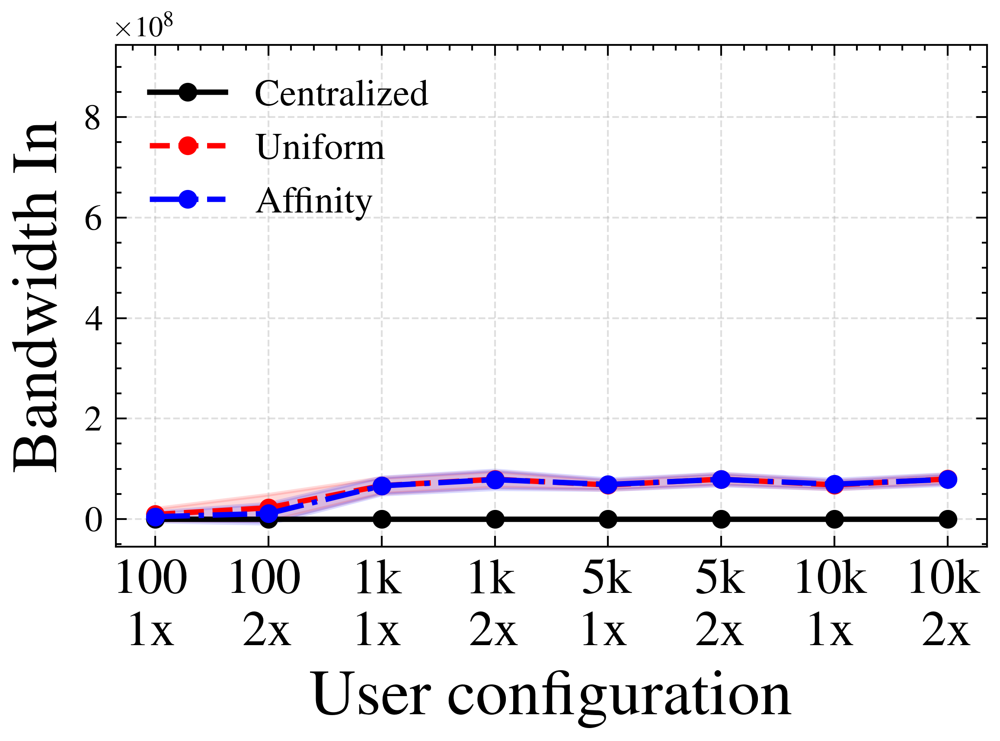

Bandwidth In — Figure 2 — server 30x  →  server_bandwidth_in_30x.pdf


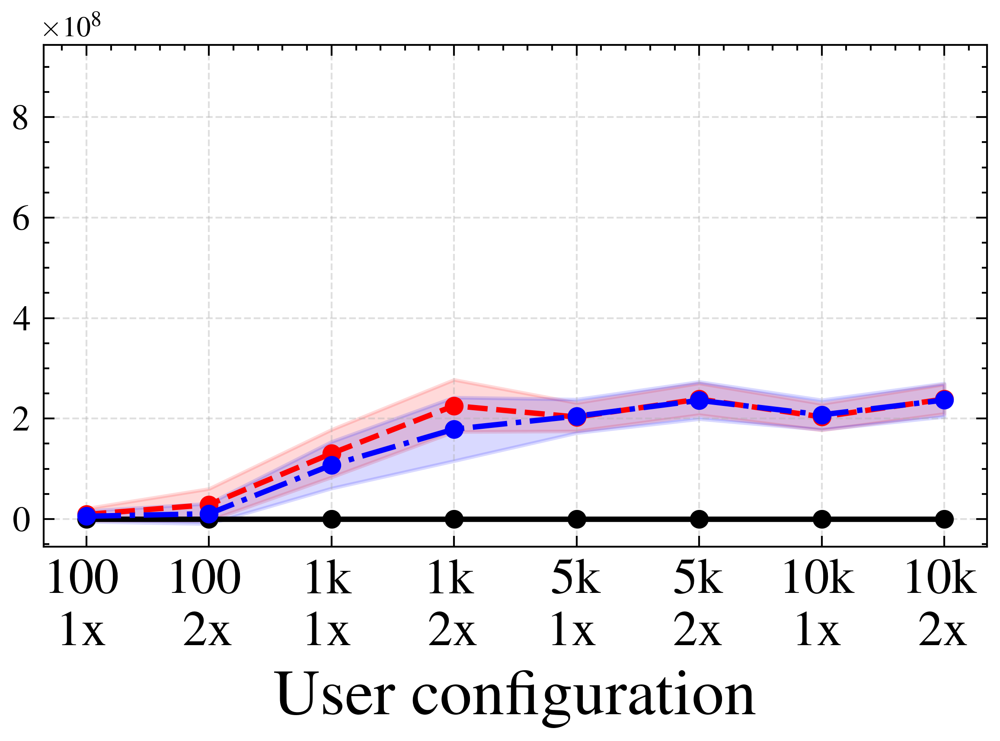

Bandwidth In — Figure 3 — server 50x  →  server_bandwidth_in_50x.pdf


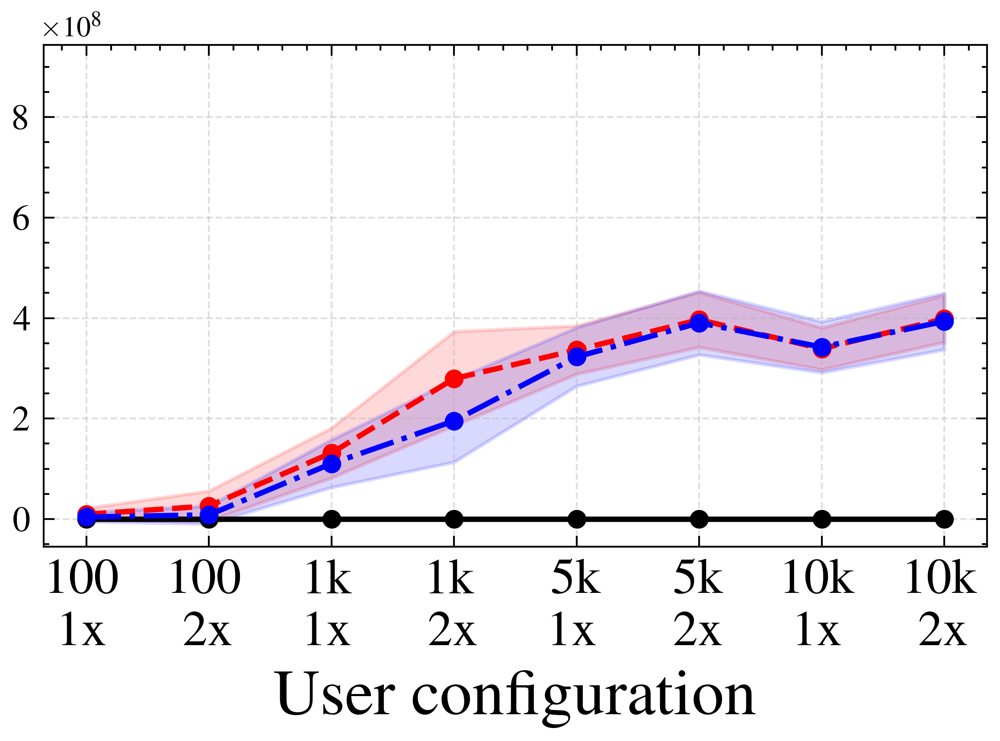

Bandwidth In — Figure 4 — server 80x  →  server_bandwidth_in_80x.pdf


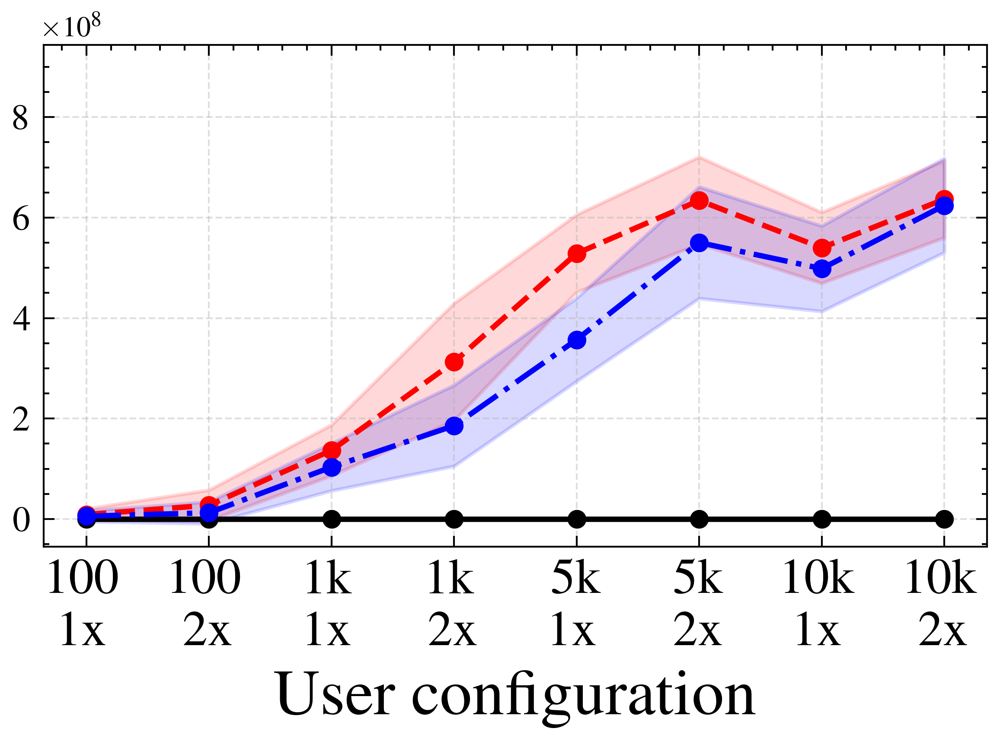

Bandwidth In — Figure 5 — server 100x  →  server_bandwidth_in_100x.pdf


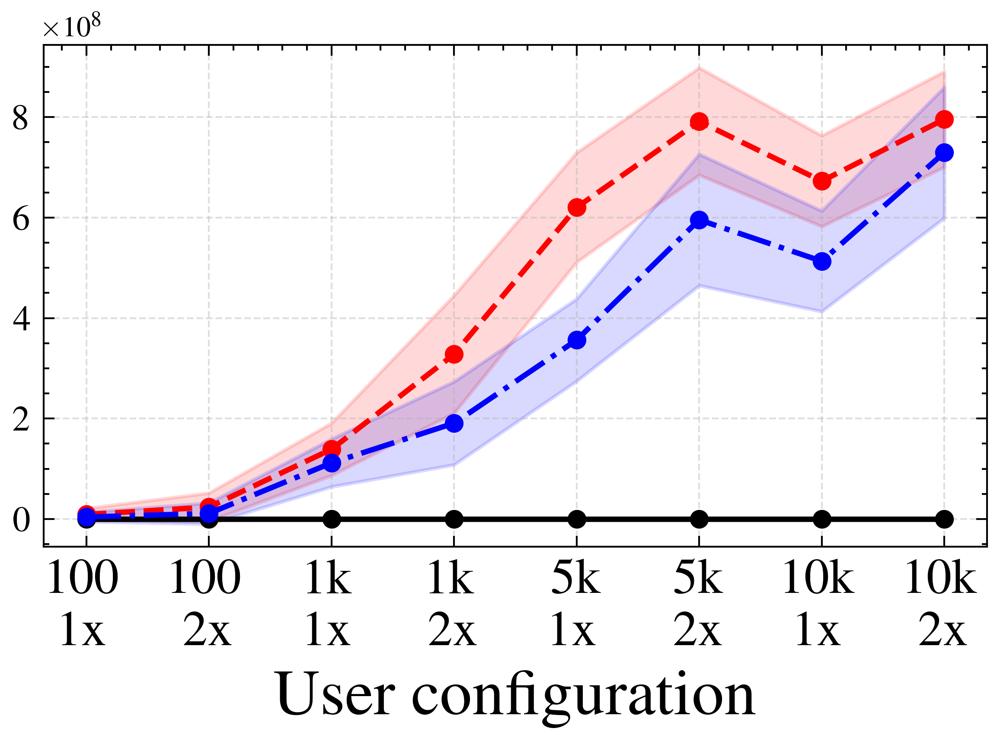

Bandwidth Out — Figure 1 — server 10x  →  server_bandwidth_out_10x.pdf


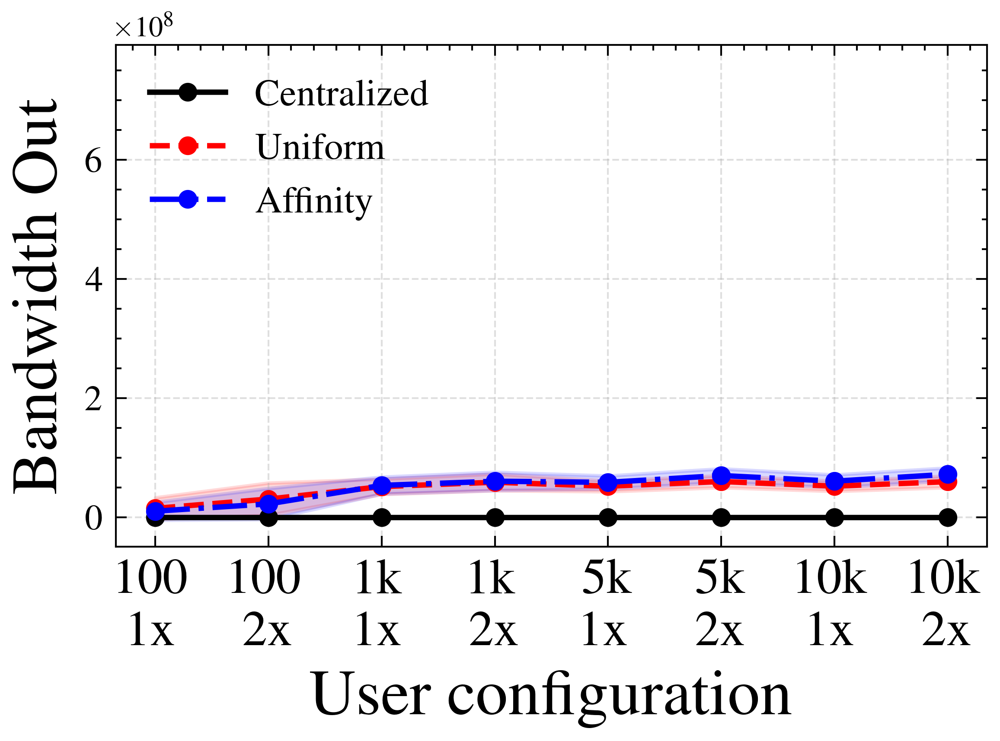

Bandwidth Out — Figure 2 — server 30x  →  server_bandwidth_out_30x.pdf


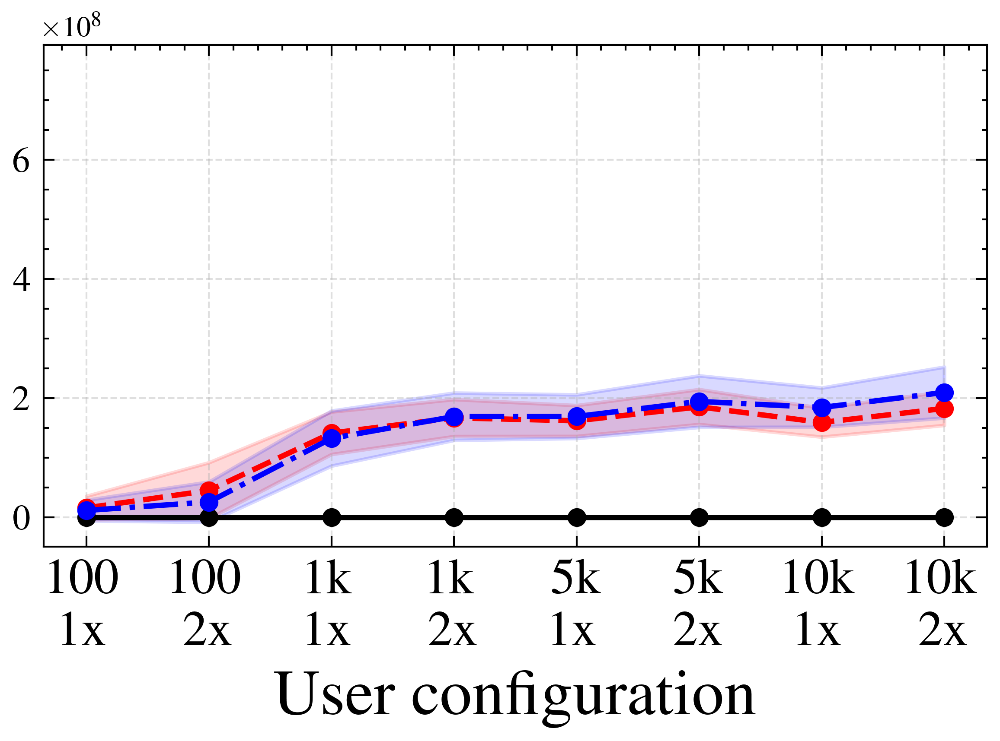

Bandwidth Out — Figure 3 — server 50x  →  server_bandwidth_out_50x.pdf


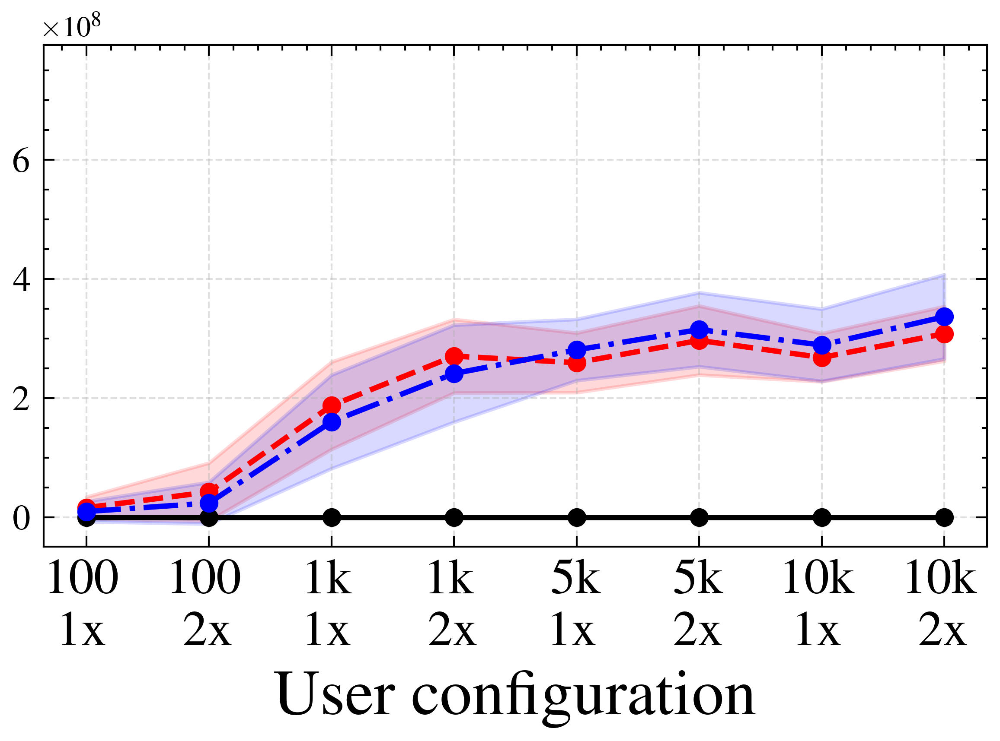

Bandwidth Out — Figure 4 — server 80x  →  server_bandwidth_out_80x.pdf


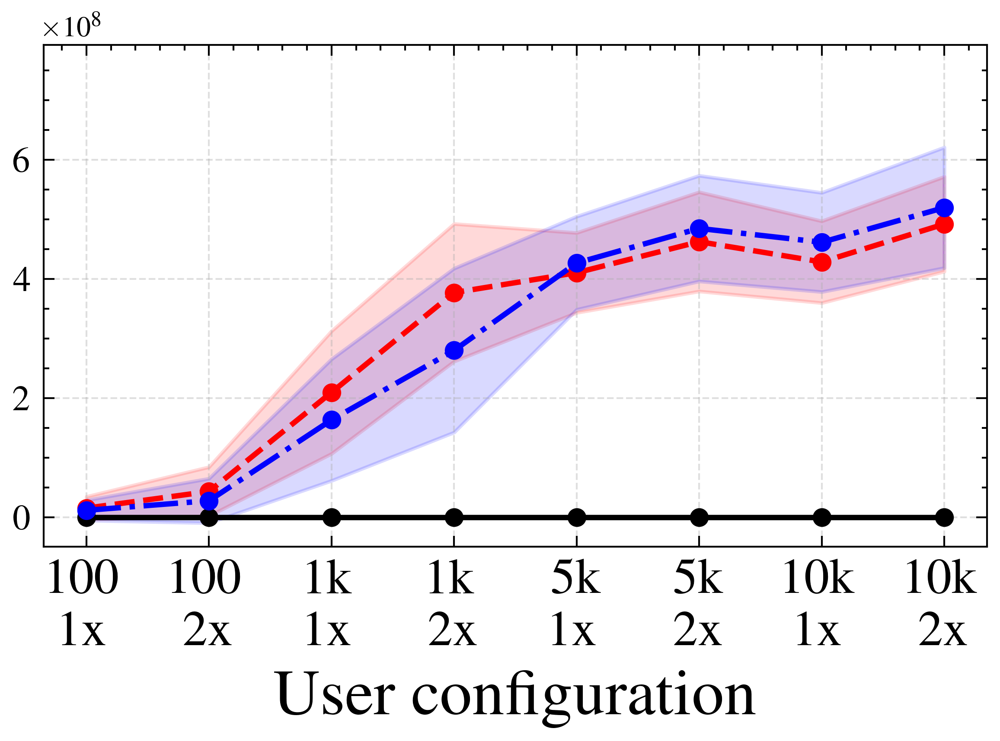

Bandwidth Out — Figure 5 — server 100x  →  server_bandwidth_out_100x.pdf


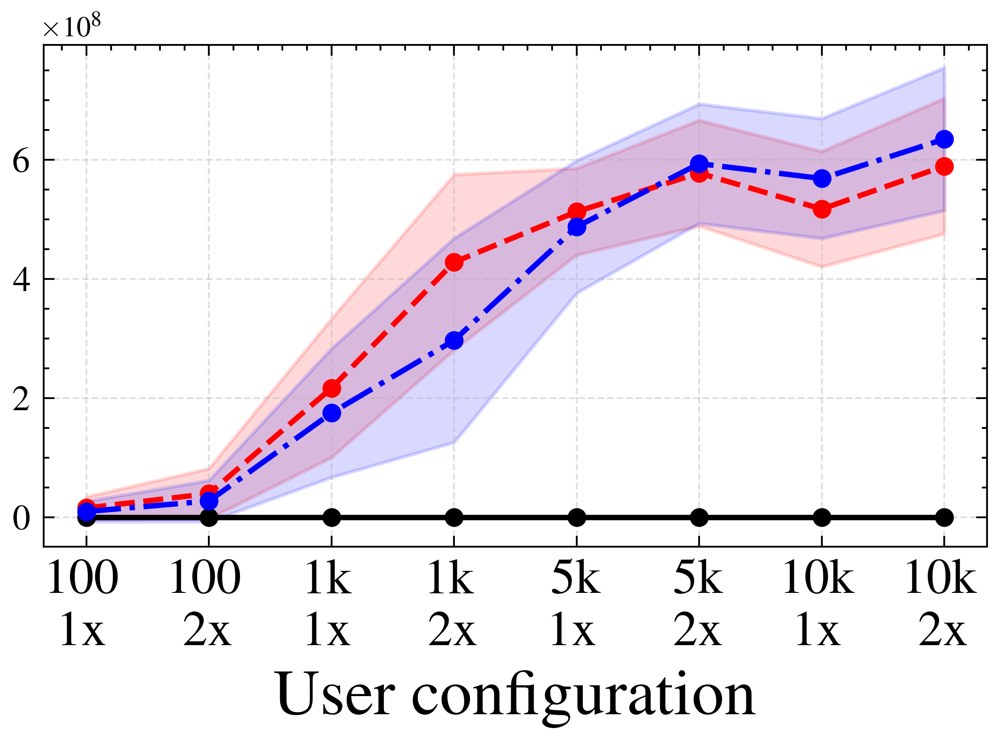

CPU (\%) — Figure 1 — server 10x  →  server_cpu_10x.pdf


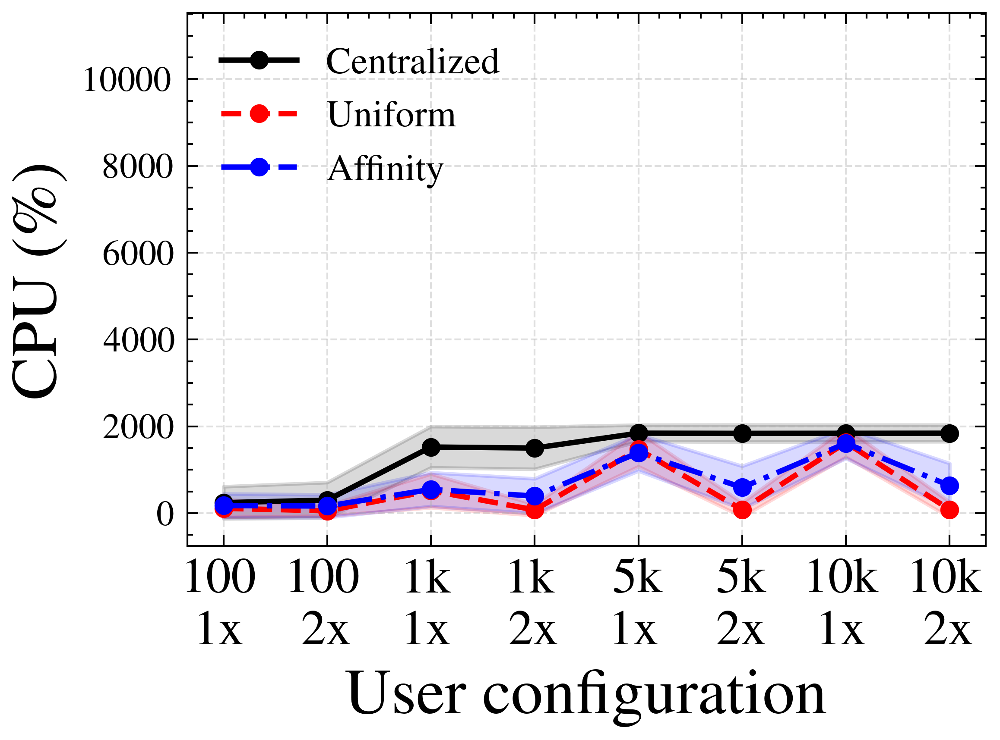

CPU (\%) — Figure 2 — server 30x  →  server_cpu_30x.pdf


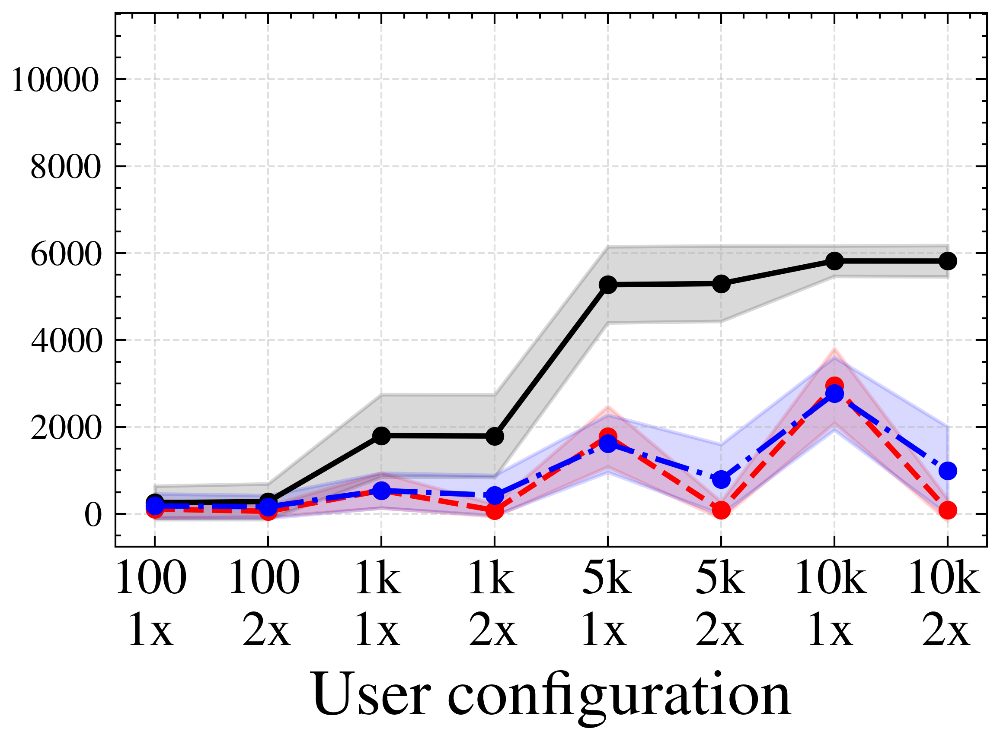

CPU (\%) — Figure 3 — server 50x  →  server_cpu_50x.pdf


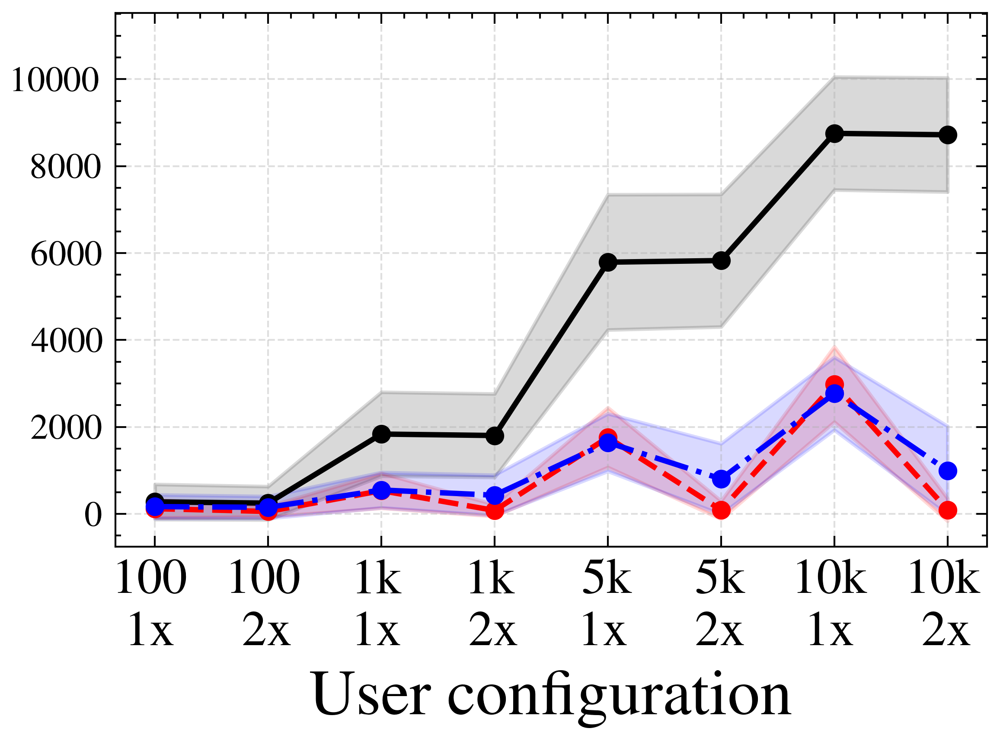

CPU (\%) — Figure 4 — server 80x  →  server_cpu_80x.pdf


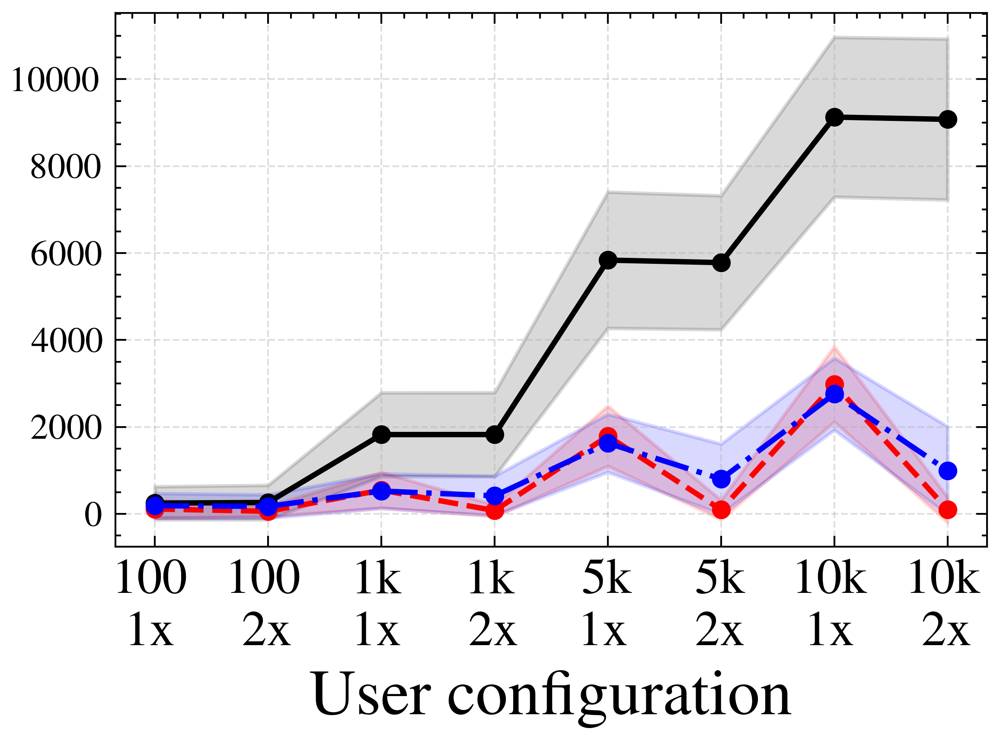

CPU (\%) — Figure 5 — server 100x  →  server_cpu_100x.pdf


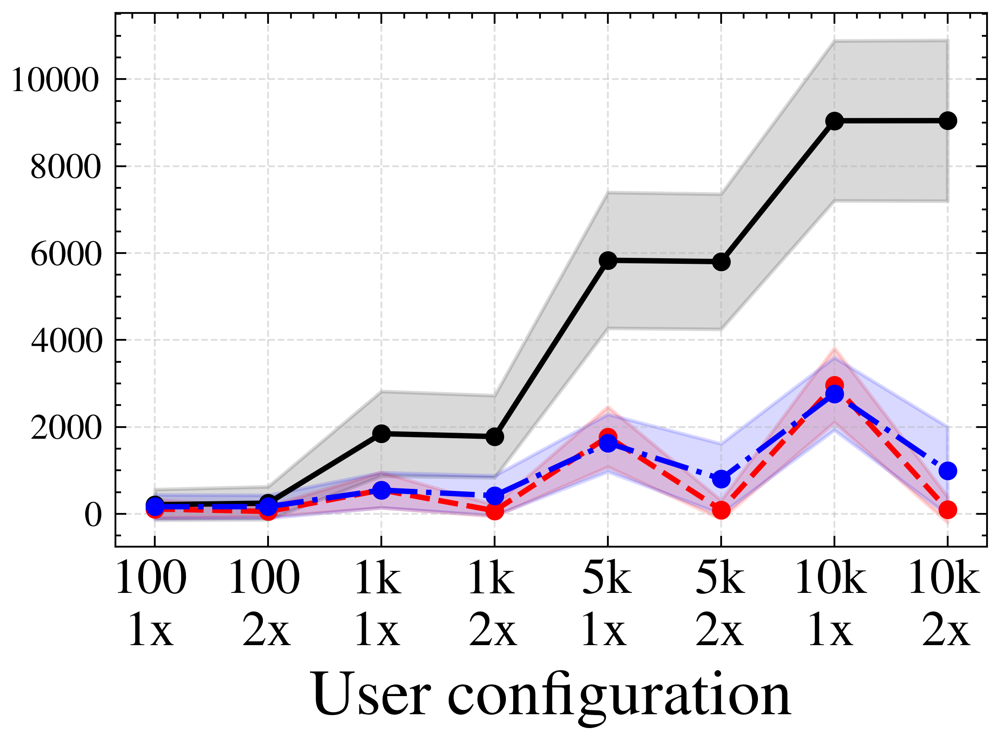

Memory (GB) — Figure 1 — server 10x  →  server_memory_10x.pdf


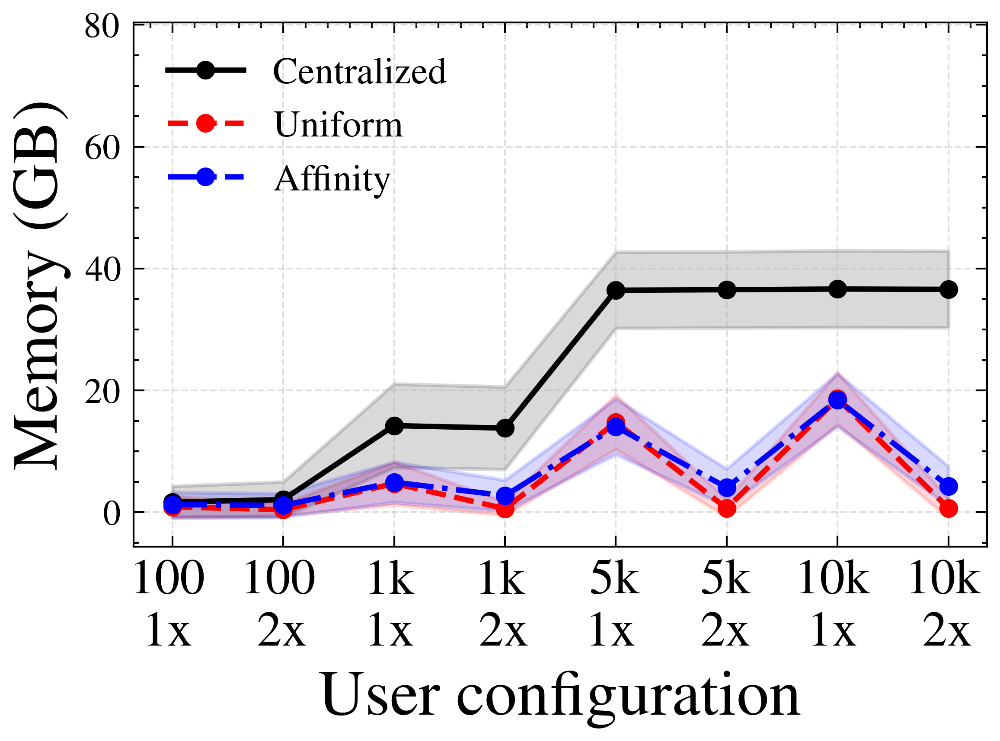

Memory (GB) — Figure 2 — server 30x  →  server_memory_30x.pdf


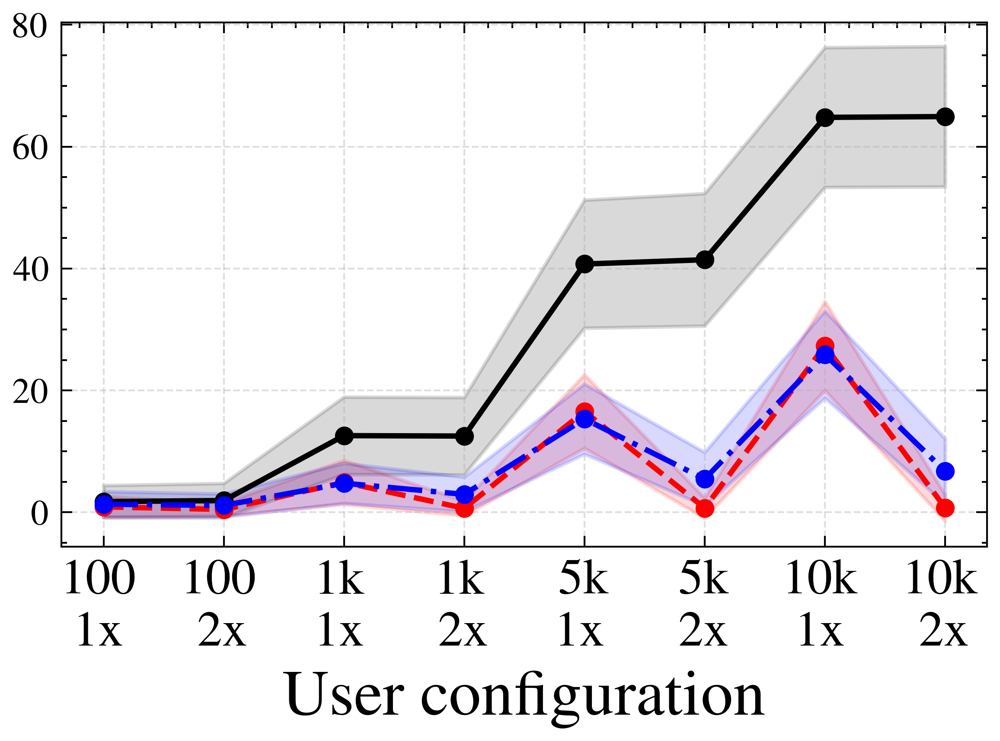

Memory (GB) — Figure 3 — server 50x  →  server_memory_50x.pdf


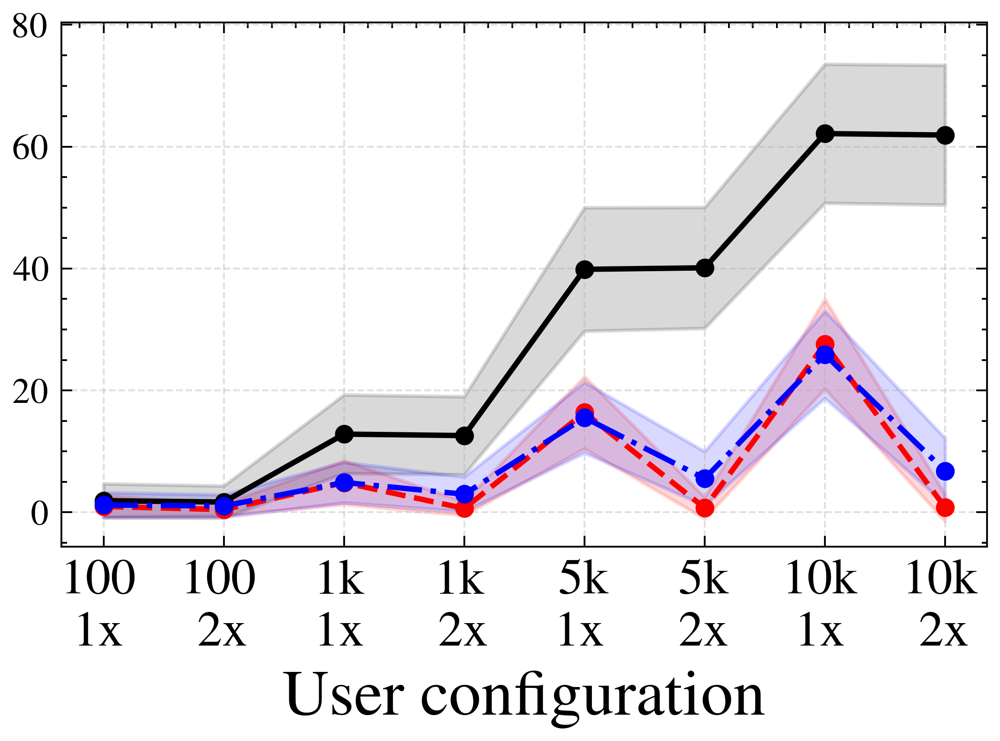

Memory (GB) — Figure 4 — server 80x  →  server_memory_80x.pdf


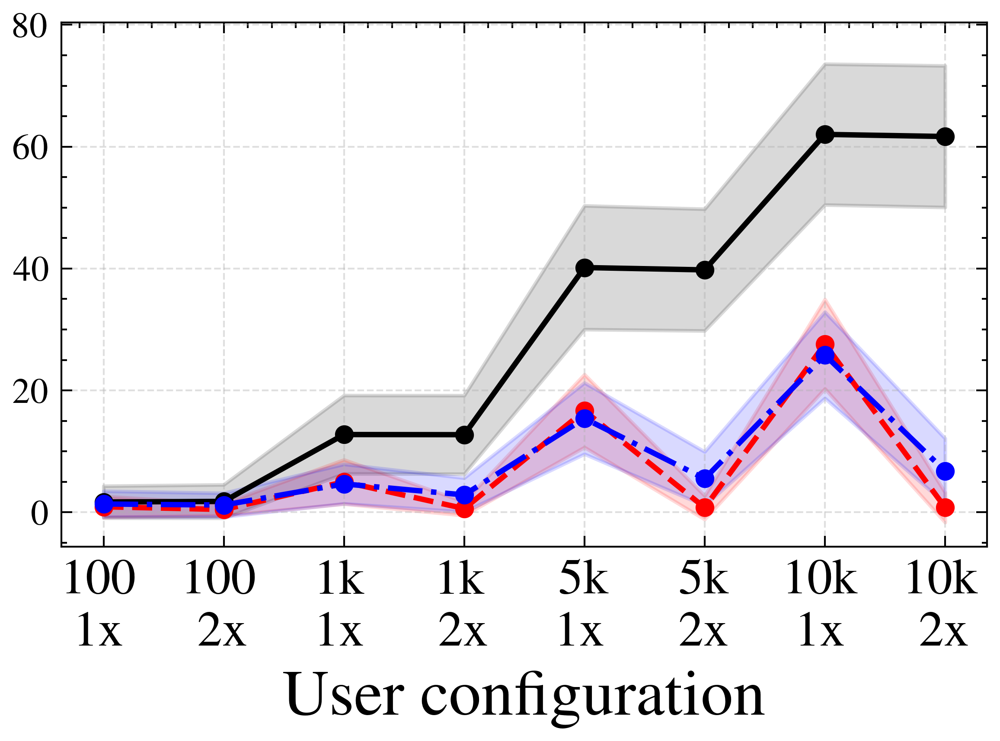

Memory (GB) — Figure 5 — server 100x  →  server_memory_100x.pdf


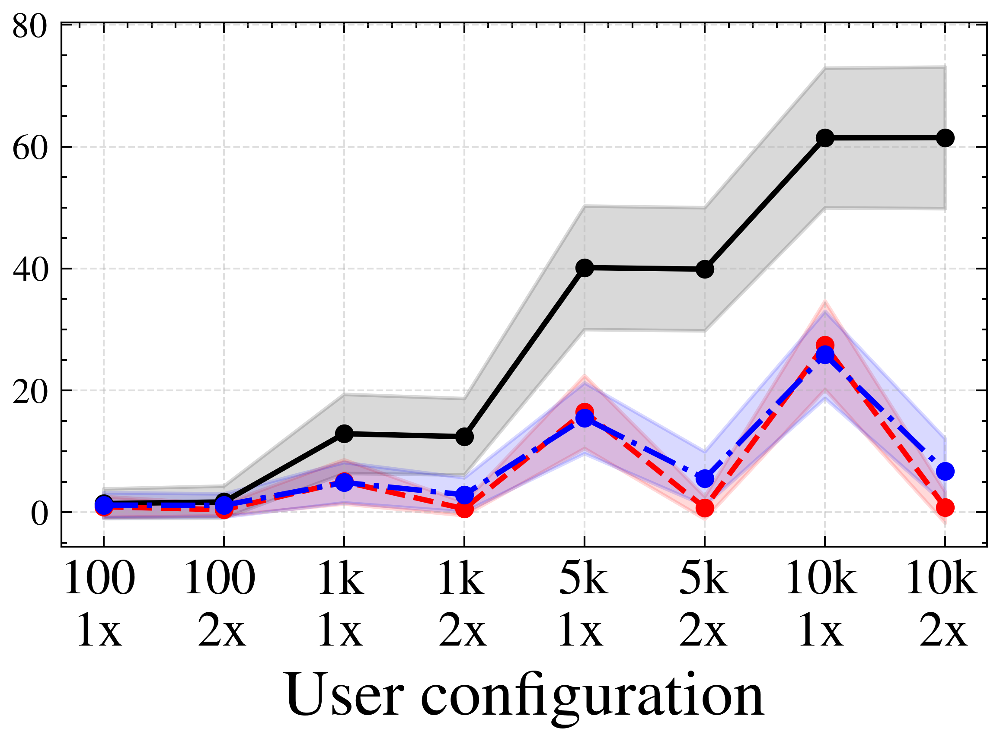

In [7]:
_theme_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
POLICY_COLORS = {policy: _theme_colors[i] for i, policy in enumerate(POLICIES)}

POLICY_LINESTYLES = {
    "centralized": "-",
    "default":     "--",
    "smart":       "-.",
    "smartx":      ":",
}

# _all_vals[(server_mult, policy)] = np.array shape (n_resources, 2, n_x_configs)
# axis 0: resource index (bw_in, bw_out, cpu, mem)
# axis 1: 0 = mean over timesteps, 1 = std over timesteps
# axis 2: x_config index
_all_vals = {}
for server_mult in server_mults:
    for policy in POLICIES:
        arr = np.full((len(RESOURCES), 2, len(x_configs)), np.nan)
        for j, (n_clients, client_mult) in enumerate(x_configs):
            key = (policy, server_mult, n_clients, client_mult)
            if key in resource_data:
                entries = resource_data[key]
                for r in range(len(RESOURCES)):
                    arr[r, 0, j] = np.nanmean([e[r * 2]     for e in entries])
                    arr[r, 1, j] = np.nanmean([e[r * 2 + 1] for e in entries])
        _all_vals[(server_mult, policy)] = arr

# Shared y-limits per resource (span of mean ± std across all configs)
_ylims = []
for r in range(len(RESOURCES)):
    finite = []
    for arr in _all_vals.values():
        for j in range(len(x_configs)):
            m, s = arr[r, 0, j], arr[r, 1, j]
            if not np.isnan(m) and not np.isnan(s):
                finite.extend([m - s, m + s])
    _y_pad = (max(finite) - min(finite)) * 0.05
    _ylims.append((min(finite) - _y_pad, max(finite) + _y_pad))

# Individual figures: one per resource per server capacity
for r, (res_label, res_fname) in enumerate(zip(RESOURCE_LABELS, RESOURCE_FNAMES)):
    ylim = _ylims[r]
    for i, server_mult in enumerate(server_mults):
        fig, ax = plt.subplots(figsize=(4, 3))

        for policy, policy_label in zip(POLICIES, POLICY_LABELS):
            color = POLICY_COLORS[policy]
            ls    = POLICY_LINESTYLES[policy]
            arr   = _all_vals[(server_mult, policy)]
            means = arr[r, 0, :]
            stds  = arr[r, 1, :]

            ax.plot(x_pos, means, color=color, linestyle=ls, marker="o",
                    markersize=4, markeredgewidth=1.2, linewidth=1.5, label=policy_label)
            ax.fill_between(x_pos, means - stds, means + stds, color=color, alpha=0.15)

        ax.set_ylim(ylim)
        ax.set_xticks(x_pos)
        ax.set_xticklabels(x_labels, fontsize=14)
        ax.tick_params(axis="y", labelsize=10)
        ax.tick_params(axis="x", which="minor", bottom=False)
        ax.set_xlabel("User configuration", fontsize=18)
        ax.grid(True, linestyle="--", alpha=0.4)

        if i == 0:
            ax.set_ylabel(res_label, fontsize=18)
            ax.legend(fontsize=10.5, loc="upper left", ncol=1)

        fname = f"server_{res_fname}_{server_mult}x.pdf"
        plt.tight_layout()
        plt.savefig(os.path.join(figures_dir, fname), bbox_inches="tight")
        print(f"{res_label} — Figure {i + 1} — server {server_mult}x  →  {fname}")
        plt.show()

In [8]:
fig, axes = plt.subplots(
    len(RESOURCES), len(server_mults),
    figsize=(3.2 * len(server_mults), 2.8 * len(RESOURCES)),
    sharex=True,
    sharey="row"
)

for row, res_label in enumerate(RESOURCE_LABELS):
    for col, server_mult in enumerate(server_mults):
        ax = axes[row, col]

        for policy, policy_label in zip(POLICIES, POLICY_LABELS):
            color = POLICY_COLORS[policy]
            ls    = POLICY_LINESTYLES[policy]
            arr   = _all_vals[(server_mult, policy)]
            means = arr[row, 0, :]
            stds  = arr[row, 1, :]

            ax.plot(x_pos, means, color=color, linestyle=ls,
                    marker="o", markersize=4, markeredgewidth=1.2,
                    linewidth=1.5, label=policy_label)
            ax.fill_between(x_pos, means - stds, means + stds, color=color, alpha=0.15)

        ax.set_xticks(x_pos)
        ax.set_xticklabels(x_labels, fontsize=7)
        ax.tick_params(axis="y", labelsize=7)
        ax.tick_params(axis="x", which="minor", bottom=False)
        ax.grid(True, linestyle="--", alpha=0.4)

        if row == 0:
            ax.set_title(f"Server {server_mult}x", fontsize=9, fontweight="bold")
        if col == 0:
            ax.set_ylabel(res_label, fontsize=9, fontweight="bold")
        if row == 0 and col == 0:
            ax.legend(fontsize=7, loc="upper left")

fig.supxlabel("User configuration (nodes, capacity)", fontsize=10, y=0.01)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "server_resources_grid.pdf"), bbox_inches="tight")
plt.show()